# 02 · Grover 搜索：用干涉放大正确答案

对应讲义实验 A · 前置：01 编程基础

**问题**：在 $N = 2^n$ 个候选中找出唯一的目标。答案一眼就能验证，却没有任何结构可以利用，经典算法只能逐个尝试，平均 $N/2$ 次；Grover 算法约 $\frac{\pi}{4}\sqrt{N}$ 次。

**直觉**：不是“同时检查所有候选”，而是干涉。每一轮先给目标的振幅打上负号（Oracle），再关于平均值翻转（扩散算子）：负的振幅变成大的正振幅，目标就被放大一点。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import numpy as np
import matplotlib.pyplot as plt
from mindquantum import Circuit, UN, H, X, Z, Simulator
from mqlab import check

## 1. 两个积木：Oracle 与扩散算子

- **Oracle** 给目标态乘上 −1。多控 Z 只翻转 $|1\cdots1\rangle$ 的符号，所以先用 X 把目标中为 0 的位翻成 1，作用多控 Z，再翻回来；
- **扩散算子** 关于均匀叠加态做反射：用 H、X 把均匀叠加态变成 $|1\cdots1\rangle$，同样加负号，再变回来。

In [2]:
def oracle(target):              # |target⟩ → −|target⟩
    n = len(target)
    flips = Circuit()
    for i, b in enumerate(reversed(target)):
        if b == '0':
            flips += X.on(i)     # 0 位先翻成 1
    mcz = Z.on(n - 1, list(range(n - 1)))
    return flips + mcz + flips

def diffusion(n):                # 关于均匀叠加态反射
    c = UN(H, n) + UN(X, n)
    c += Z.on(n - 1, list(range(n - 1)))   # 多控 Z
    return c + UN(X, n) + UN(H, n)

def grover(target, k):
    n = len(target)
    circ = UN(H, n)              # 均匀叠加
    for _ in range(k):           # k 次 Grover 迭代
        circ += oracle(target)
        circ += diffusion(n)
    return circ

画出 Oracle 的线路：

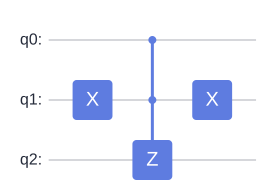

In [3]:
oracle('101').svg()

目标 `101` 按 q2 q1 q0 书写，为 0 的是 q1，所以 X 加在 q1 上，夹住中间的多控 Z。

## 2. 直觉：看振幅怎么变

从均匀叠加出发，依次作用 Oracle 和扩散算子，画出 8 个振幅（Grover 算法的振幅都是实数）：

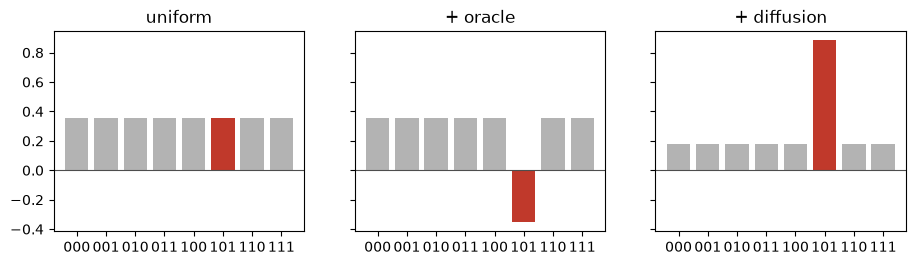

In [4]:
stages = {'uniform': UN(H, 3)}
stages['+ oracle'] = stages['uniform'] + oracle('101')
stages['+ diffusion'] = stages['+ oracle'] + diffusion(3)

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), sharey=True)
for ax, (name, c) in zip(axes, stages.items()):
    sim = Simulator('mqvector', 3)
    sim.apply_circuit(c)
    amp = sim.get_qs().real
    amp *= np.sign(amp[0])               # 去掉全局相位（见下文）
    colors = ['#c0392b' if i == 5 else '0.7' for i in range(8)]
    ax.bar([f'{i:03b}' for i in range(8)], amp, color=colors)
    ax.axhline(0, color='0.3', lw=0.8)
    ax.set_title(name)
plt.show()

Oracle 只改符号、不改概率；扩散算子把“负的”变成“大的”。一轮之后，`101` 的振幅从 0.354 升到 0.884，概率从 12.5% 升到 78.1%。再来一轮会怎样？

（按这种写法，扩散算子还会给所有振幅乘上一个全局相位 −1。全局相位不影响任何测量结果，画图时把它去掉了。）

## 3. 运行：两轮迭代

下面是完整的程序：两轮迭代后测量 1,000 次。

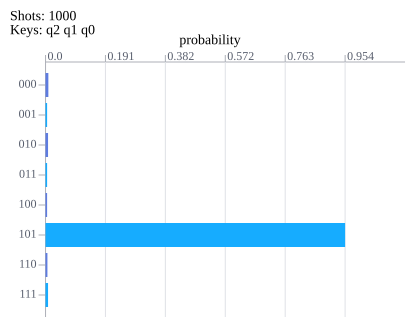

In [5]:
circ = grover('101', k=2)
circ.measure_all()
sim = Simulator('mqvector', circ.n_qubits)
res = sim.sampling(circ, shots=1000, seed=7)
res.svg()

两轮之后，测到 `101` 的理论概率是 94.5%。

### 现场改一改：先预测，再运行

直接修改上面单元格的第一行，每次改一处，先写下预测再运行：

1. **迭代 4 次**：`circ = grover('101', k=4)`。测到 `101` 的概率会怎样？　A 接近 100%　B 仍约 94.5%　C 接近 0
2. **换一个目标**：`circ = grover('011', k=2)`。Oracle 会在哪个比特上加 X？　A q0　B q1　C q2（把第 1 节画线路的 `oracle('101')` 改成 `oracle('011')` 验证）
3. **两个目标，只迭代 1 次**：`circ = UN(H, 3) + oracle('101') + oracle('011') + diffusion(3)`。测到两个目标之一的概率？　A 50%　B 78.1%　C 100%

<details><summary>答案</summary>

1. C：只剩约 1%（理论值 1.2%）。每轮朝目标转过 2θ ≈ 41.4°，初始角 θ ≈ 20.7°，4 轮后已转到 186.3°，转过头了（见第 4 节的曲线）。
2. C：`'011'` 按 q2 q1 q0 书写，为 0 的是 q2，X 只加在 q2 上；测到 `011` 的概率同样约 94.5%。
3. C：100%，两个目标各占约一半。M 个目标时 $\sin\theta = \sqrt{M/N}$，这里 $\sin\theta = 1/2$，θ = 30°；一次迭代转过 60°，恰好从 30° 转到 90°。
</details>

## 4. 深入：迭代不是越多越好

成功率为 $\sin^2((2k+1)\theta)$，其中 $\sin\theta = 1/\sqrt{N}$。每一轮把态矢量朝目标转过 $2\theta$，转过头，概率就会下降。

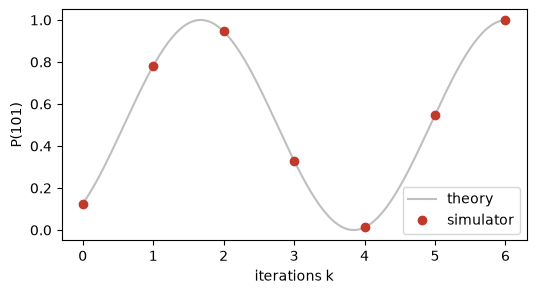

In [6]:
theta = np.arcsin(1 / np.sqrt(8))
p_sim = []
for k in range(7):
    sim = Simulator('mqvector', 3)
    sim.apply_circuit(grover('101', k))
    p_sim.append(abs(sim.get_qs()[5]) ** 2)    # 下标 5 = '101'

kk = np.linspace(0, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(kk, np.sin((2 * kk + 1) * theta) ** 2, color='0.75', label='theory')
plt.plot(range(7), p_sim, 'o', color='#c0392b', label='simulator')
plt.xlabel('iterations k')
plt.ylabel('P(101)')
plt.legend()
plt.show()

最优迭代次数约为 $\frac{\pi}{4\theta} - \frac{1}{2} \approx \frac{\pi}{4}\sqrt{N}$：N = 8 时是 2 次。

## 练习 · 最优迭代次数

4 个比特、目标 `'0110'`，最优迭代次数是多少？先用公式算出来，再把第 3 节的程序改成 `grover('0110', k)` 运行验证。

In [7]:
# 练习：算出 k（整数）
### BEGIN SOLUTION
theta = np.arcsin(1 / np.sqrt(16))
k = round(np.pi / (4 * theta) - 0.5)
### STUDENT: k = ...
### END SOLUTION
check.grover_iterations(k)

✅ 通过：N = 16 时最优迭代 3 次，成功率 96.1%


## 小结

- Oracle 只改相位，扩散算子把相位差变成振幅差；两步交替，目标的振幅一轮轮增大。
- 最优迭代次数约为 $\frac{\pi}{4}\sqrt{N}$：查询次数从 $N/2$ 降到 $\sqrt{N}$ 量级，是**二次加速**。
- 在真机上，多控 Z 要分解成许多两比特门，线路很深：Grover 算法要在容错硬件上才有实际意义。